In [ ]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch

warnings.filterwarnings("ignore", category=FutureWarning)
Path("img").mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#eef2f7", "grid.linewidth": 0.9,
    "axes.axisbelow": True, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
})
BLUE, ORANGE, TEAL = "#2563eb", "#f97316", "#0d9488"
PURPLE, RED = "#7c3aed", "#dc2626"
GREY, INK = "#94a3b8", "#1e293b"

In [24]:
DATA = next((p for p in ["data/city_day.csv", "city_day.csv"] if Path(p).exists()), None)
assert DATA, "city_day.csv not found. Put it in a data/ folder next to this notebook."

raw = pd.read_csv(DATA, parse_dates=["Date"])
print("file     :", DATA)
print("shape    :", raw.shape)
print("columns  :", raw.columns.tolist())
print("dates    :", raw.Date.min().date(), "->", raw.Date.max().date())
print("cities   :", raw.City.nunique())
raw.head()

file     : data/city_day.csv
shape    : (29531, 16)
columns  : ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
dates    : 2015-01-01 -> 2020-07-01
cities   : 26


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


% missing per column
Xylene        61.3
PM10          37.7
NH3           35.0
Toluene       27.2
Benzene       19.0
AQI           15.9
AQI_Bucket    15.9
PM2.5         15.6
NOx           14.2
O3            13.6
SO2           13.1
NO2           12.1
NO            12.1
CO             7.0
Date           0.0
City           0.0


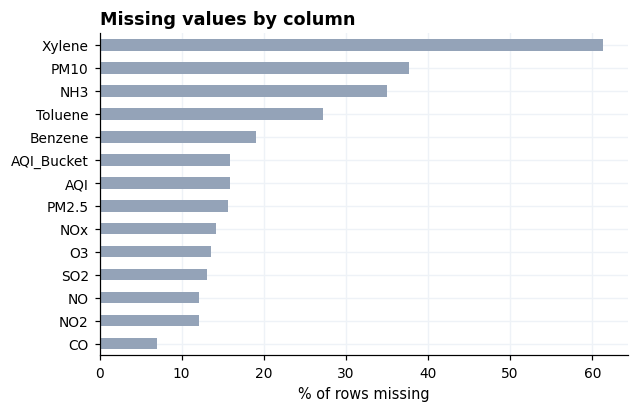


Coverage per city
                        first       last  rows
City                                          
Ahmedabad          2015-01-01 2020-07-01  2009
Aizawl             2020-03-11 2020-07-01   113
Amaravati          2017-11-24 2020-07-01   951
Amritsar           2017-02-27 2020-07-01  1221
Bengaluru          2015-01-01 2020-07-01  2009
Bhopal             2019-09-17 2020-07-01   289
Brajrajnagar       2017-12-07 2020-07-01   938
Chandigarh         2019-09-02 2020-07-01   304
Chennai            2015-01-01 2020-07-01  2009
Coimbatore         2019-06-12 2020-07-01   386
Delhi              2015-01-01 2020-07-01  2009
Ernakulam          2020-01-22 2020-07-01   162
Gurugram           2015-11-27 2020-07-01  1679
Guwahati           2019-02-16 2020-07-01   502
Hyderabad          2015-01-04 2020-07-01  2006
Jaipur             2017-06-14 2020-07-01  1114
Jorapokhar         2017-04-20 2020-07-01  1169
Kochi              2020-01-22 2020-07-01   162
Kolkata            2018-04-10 2020-07-01 

In [25]:
miss = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
print("% missing per column")
print(miss.to_string())

fig, ax = plt.subplots(figsize=(6.2, 3.8))
miss[miss > 0].sort_values().plot.barh(ax=ax, color=GREY)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column", loc="left")
plt.show()

print("\nCoverage per city")
print(raw.groupby("City").Date.agg(first="min", last="max", rows="count").to_string())

In [26]:
both = raw.dropna(subset=["NO", "CO"]).copy()
both["same"] = both.NO == both.CO
print(f"rows with both NO and CO: {len(both)}")
print(f"identical NO == CO      : {both.same.sum()} ({both.same.mean() * 100:.1f}%)")

print("\n% identical, by city")
print((both.groupby("City").same.mean() * 100).round(1).sort_values(ascending=False).to_string())

print("\n% identical, by year")
print((both.groupby(both.Date.dt.year).same.mean() * 100).round(1).to_string())

print("\ncorrelation NO vs CO:", round(raw[["NO", "CO"]].corr().iloc[0, 1], 3))

rows with both NO and CO: 25520
identical NO == CO      : 1322 (5.2%)

% identical, by city
City
Ahmedabad             94.1
Thiruvananthapuram     0.4
Coimbatore             0.3
Aizawl                 0.0
Bengaluru              0.0
Amaravati              0.0
Bhopal                 0.0
Brajrajnagar           0.0
Chandigarh             0.0
Amritsar               0.0
Chennai                0.0
Delhi                  0.0
Gurugram               0.0
Ernakulam              0.0
Hyderabad              0.0
Jaipur                 0.0
Jorapokhar             0.0
Guwahati               0.0
Kochi                  0.0
Kolkata                0.0
Mumbai                 0.0
Lucknow                0.0
Patna                  0.0
Shillong               0.0
Talcher                0.0
Visakhapatnam          0.0

% identical, by year
Date
2015    13.0
2016     4.8
2017     1.9
2018     6.3
2019     5.1
2020     2.3

correlation NO vs CO: 0.213


In [27]:
RENAME = {"PM2.5": "pm25", "PM10": "pm10", "NO2": "no2", "CO": "co",
          "SO2": "so2", "O3": "o3", "AQI": "aqi", "AQI_Bucket": "bucket"}
absent = [c for c in RENAME if c not in raw.columns]
assert not absent, f"expected columns not found: {absent}"

df = raw.rename(columns=RENAME).sort_values(["City", "Date"]).reset_index(drop=True)
POLL = ["pm25", "pm10", "no2", "co", "so2", "o3", "aqi"]

# 1. negative readings are sensor errors
neg = int((df[POLL] < 0).sum().sum())
df[POLL] = df[POLL].mask(df[POLL] < 0)
print("negative readings set to missing:", neg)

# 2. Ahmedabad CO is a copy of NO (94% identical), so it is not a real CO reading
amd = df.City == "Ahmedabad"
print("Ahmedabad CO values removed:", int(df.loc[amd, "co"].notna().sum()))
df.loc[amd, "co"] = np.nan

# 3. fill gaps of up to 3 days, inside one city only
for c in POLL:
    df[c] = df.groupby("City")[c].transform(
        lambda s: s.interpolate(limit=3, limit_area="inside"))

print("\n% still missing after interpolation")
print((df[POLL].isna().mean() * 100).round(1).to_string())

# 4. what each choice of 'required columns' would leave (nothing is dropped yet)
options = {
    "A: pm25, pm10, no2, co, aqi": ["pm25", "pm10", "no2", "co", "aqi"],
    "B: pm25, pm10, no2, aqi":     ["pm25", "pm10", "no2", "aqi"],
    "C: pm25, no2, aqi":           ["pm25", "no2", "aqi"],
}
out = []
for name, core in options.items():
    ok = df.dropna(subset=core)
    d = ok.groupby("City").size()
    big = d[d >= 365].index
    out.append({"required columns": name,
                "rows kept": len(ok),
                "cities >=365 days": len(big),
                "rows in those cities": int(ok.City.isin(big).sum()),
                "Ahmedabad rows": int((ok.City == "Ahmedabad").sum())})
print("\n" + pd.DataFrame(out).to_string(index=False))

negative readings set to missing: 0
Ahmedabad CO values removed: 1400

% still missing after interpolation
pm25    13.9
pm10    36.0
no2     10.1
co       9.8
so2     10.7
o3      11.2
aqi     12.9

           required columns  rows kept  cities >=365 days  rows in those cities  Ahmedabad rows
A: pm25, pm10, no2, co, aqi      17041                 15                 15186               0
    B: pm25, pm10, no2, aqi      17701                 17                 16015             412
          C: pm25, no2, aqi      24830                 20                 23652            1392


In [28]:
CORE = ["pm25", "no2", "aqi"]

n0 = len(df)
df = df.dropna(subset=CORE)
print(f"rows dropped (pm25, no2 or aqi still missing): {n0 - len(df)} | kept: {len(df)}")

days = df.groupby("City").size()
print("\nusable days per city")
print(days.sort_values().to_string())
small = days[days < 365]
print("\ncities dropped (<365 usable days):", small.to_dict())
df = df[df.City.isin(days[days >= 365].index)].copy()

df["year"], df["month"] = df.Date.dt.year, df.Date.dt.month
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
          6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
          10: "Post-monsoon", 11: "Post-monsoon"}
SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
df["season"] = df.month.map(SEASON)

# Two indices, each one pollutant scaled to 0-100 (the 'full at' levels are my judgement)
FULL = {"pm25": 120, "no2": 180}
df["particulate_idx"] = (df.pm25 / FULL["pm25"]).clip(0, 1) * 100
df["gas_idx"]         = (df.no2 / FULL["no2"]).clip(0, 1) * 100

print("\nfinal:", df.shape, "| cities:", df.City.nunique(),
      "|", df.Date.min().date(), "->", df.Date.max().date())
print(df[["aqi", "pm25", "no2", "particulate_idx", "gas_idx"]]
      .describe().loc[["mean", "std", "min", "50%", "max"]].round(1).to_string())

# pre-check for the Apr-May lockdown comparison
def win(y):
    return df[(df.year == y) & (df.month.isin([4, 5]))]
cover = pd.concat([win(2019).groupby("City").size().rename("apr_may_2019"),
                   win(2020).groupby("City").size().rename("apr_may_2020")],
                  axis=1).fillna(0).astype(int)
print("\ncities with >=30 days in both Apr-May windows:", int((cover >= 30).all(axis=1).sum()))
print(cover.to_string())

rows dropped (pm25, no2 or aqi still missing): 4701 | kept: 24830

usable days per city
City
Aizawl                 112
Ernakulam              116
Kochi                  158
Shillong               220
Bhopal                 281
Chandigarh             291
Coimbatore             372
Jorapokhar             381
Guwahati               501
Talcher                676
Brajrajnagar           727
Kolkata                757
Mumbai                 761
Amaravati              904
Thiruvananthapuram    1071
Amritsar              1100
Jaipur                1106
Visakhapatnam         1241
Ahmedabad             1392
Gurugram              1504
Patna                 1538
Bengaluru             1895
Hyderabad             1901
Chennai               1903
Lucknow               1914
Delhi                 2008

cities dropped (<365 usable days): {'Aizawl': 112, 'Bhopal': 281, 'Chandigarh': 291, 'Ernakulam': 116, 'Kochi': 158, 'Shillong': 220}



final: (23652, 21) | cities: 20 | 2015-01-01 -> 2020-07-01
         aqi   pm25    no2  particulate_idx  gas_idx
mean   171.1   69.2   30.0             48.7     16.6
std    144.1   65.4   24.8             29.1     13.5
min     22.0    0.0    0.0              0.0      0.0
50%    120.0   49.8   23.2             41.5     12.9
max   2049.0  950.0  362.2            100.0    100.0

cities with >=30 days in both Apr-May windows: 17
                    apr_may_2019  apr_may_2020
City                                          
Ahmedabad                     59            61
Amaravati                     61            61
Amritsar                      61            58
Bengaluru                     61            61
Brajrajnagar                  50             7
Chennai                       61            61
Delhi                         61            61
Gurugram                      61            61
Guwahati                      61            61
Hyderabad                     61            61
Jaipur 

In [29]:
print("final shape :", df.shape, "| cities:", df.City.nunique())
print("dates       :", df.Date.min().date(), "->", df.Date.max().date())
print(df[["aqi", "pm25", "no2", "particulate_idx", "gas_idx"]]
      .describe().loc[["mean", "50%", "max"]].round(1).to_string())

ok = cover[(cover >= 30).all(axis=1)]
print("\ncities usable for lockdown comparison:", len(ok))
print(ok.index.tolist())

final shape : (23652, 21) | cities: 20
dates       : 2015-01-01 -> 2020-07-01
         aqi   pm25    no2  particulate_idx  gas_idx
mean   171.1   69.2   30.0             48.7     16.6
50%    120.0   49.8   23.2             41.5     12.9
max   2049.0  950.0  362.2            100.0    100.0

cities usable for lockdown comparison: 17
['Ahmedabad', 'Amaravati', 'Amritsar', 'Bengaluru', 'Chennai', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


In [30]:
print("AQI   > 500 :", int((df.aqi > 500).sum()), "rows of", len(df))
print("PM2.5 > 500 :", int((df.pm25 > 500).sum()), "rows")
print("NO2   > 200 :", int((df.no2 > 200).sum()), "rows")

print("\ntop 12 AQI values")
print(df.sort_values("aqi", ascending=False)
        [["City", "Date", "pm25", "no2", "aqi", "bucket"]].head(12).to_string(index=False))

print("\nAQI > 500, by city")
print(df[df.aqi > 500].groupby("City").size().sort_values(ascending=False).to_string())

print("\nAQI > 500, by year")
print(df[df.aqi > 500].groupby("year").size().to_string())

AQI   > 500 : 560 rows of 23652
PM2.5 > 500 : 36 rows
NO2   > 200 : 29 rows

top 12 AQI values
     City       Date   pm25    no2    aqi bucket
Ahmedabad 2018-02-19 242.66 199.17 2049.0 Severe
Ahmedabad 2018-02-10 185.77 172.84 1917.0 Severe
Ahmedabad 2016-07-14  38.13  48.06 1842.0 Severe
Ahmedabad 2017-11-14 207.19 146.18 1747.0 Severe
Ahmedabad 2019-01-03 131.50  75.82 1719.0 Severe
Ahmedabad 2018-11-18 127.46  77.65 1672.0 Severe
Ahmedabad 2018-11-21  86.52  66.59 1646.0 Severe
Ahmedabad 2018-11-08 205.21 100.87 1630.0 Severe
Ahmedabad 2018-02-01 189.12 178.13 1613.0 Severe
Ahmedabad 2019-10-13 194.36 207.05 1595.0 Severe
Ahmedabad 2017-11-13 119.17  98.11 1577.0 Severe
Ahmedabad 2018-10-23 129.98  97.96 1561.0 Severe

AQI > 500, by city
City
Ahmedabad    432
Delhi         48
Gurugram      27
Patna         25
Lucknow       15
Hyderabad      4
Amritsar       4
Talcher        3
Guwahati       2

AQI > 500, by year
year
2015     55
2016     62
2017     64
2018    201
2019    160
2020 

In [31]:

amd = raw[raw.City == "Ahmedabad"]
hi = amd[amd.AQI > 500]
print("Ahmedabad rows with AQI > 500 (raw):", len(hi))
print("  their raw CO   : median", round(hi.CO.median(), 1), "| max", round(hi.CO.max(), 1))
print("  their raw PM2.5: median", round(hi["PM2.5"].median(), 1))

print("\nAhmedabad: correlation of AQI with each pollutant (raw file)")
print(amd[["AQI", "PM2.5", "NO2", "CO", "NO"]].corr().round(2)["AQI"].to_string())

print("\nAQI vs PM2.5 correlation, city by city (cleaned data)")
c = {city: round(g.aqi.corr(g.pm25), 2) for city, g in df.groupby("City")}
print(pd.Series(c).sort_values().to_string())

oth = df[(df.aqi > 500) & (df.City != "Ahmedabad")]
print("\nAQI > 500 outside Ahmedabad:", len(oth), "rows")
print("  their PM2.5: median", round(oth.pm25.median(), 1), "| min", round(oth.pm25.min(), 1))

Ahmedabad rows with AQI > 500 (raw): 412
  their raw CO   : median 37.4 | max 145.3
  their raw PM2.5: median 88.2

Ahmedabad: correlation of AQI with each pollutant (raw file)
AQI      1.00
PM2.5    0.49
NO2      0.53
CO       0.84
NO       0.84

AQI vs PM2.5 correlation, city by city (cleaned data)
Coimbatore            0.37
Bengaluru             0.41
Ahmedabad             0.48
Amritsar              0.58
Guwahati              0.60
Chennai               0.69
Jorapokhar            0.79
Hyderabad             0.80
Gurugram              0.81
Thiruvananthapuram    0.82
Talcher               0.83
Jaipur                0.85
Brajrajnagar          0.88
Visakhapatnam         0.88
Delhi                 0.88
Amaravati             0.91
Lucknow               0.92
Patna                 0.92
Mumbai                0.94
Kolkata               0.97

AQI > 500 outside Ahmedabad: 128 rows
  their PM2.5: median 396.8 | min 14.9


In [32]:
amd = df.City == "Ahmedabad"
print("Ahmedabad AQI removed (driven by copied CO):", int(df.loc[amd, "aqi"].notna().sum()))
df.loc[amd, "aqi"] = np.nan

n_hi = int((df.aqi > 500).sum())
df.loc[df.aqi > 500, "aqi"] = np.nan
print("AQI above 500 (outside CPCB scale) removed:", n_hi)
print("AQI rows now usable:", int(df.aqi.notna().sum()), "of", len(df))

Ahmedabad AQI removed (driven by copied CO): 1392
AQI above 500 (outside CPCB scale) removed: 128
AQI rows now usable: 22132 of 23652


In [33]:
print("=" * 70)
print("1. PROFILE")
print("=" * 70)
print(f"city-days {len(df):,} | cities {df.City.nunique()} | {df.Date.min().date()} -> {df.Date.max().date()}")
print(f"AQI (excl. Ahmedabad) mean {df.aqi.mean():.0f}, median {df.aqi.median():.0f}")
print(f"PM2.5 mean {df.pm25.mean():.1f}, median {df.pm25.median():.1f} | NO2 mean {df.no2.mean():.1f}, median {df.no2.median():.1f}")
print(f"days with AQI > 200 (poor or worse): {(df.aqi.dropna() > 200).mean() * 100:.1f}%")

by_season = df.groupby("season").agg(
    days=("pm25", "size"), aqi=("aqi", "mean"), pm25=("pm25", "mean"),
    no2=("no2", "mean")).reindex(SEASONS).round(1)
print("\nby season")
print(by_season.to_string())

by_city = df.groupby("City").agg(days=("pm25", "size"), aqi=("aqi", "mean"),
    pm25=("pm25", "mean"), no2=("no2", "mean")).round(1).sort_values("pm25", ascending=False)
print("\nby city (highest PM2.5 first)")
print(by_city.to_string())

1. PROFILE
city-days 23,652 | cities 20 | 2015-01-01 -> 2020-07-01
AQI (excl. Ahmedabad) mean 151, median 115
PM2.5 mean 69.2, median 49.8 | NO2 mean 30.0, median 23.2
days with AQI > 200 (poor or worse): 23.5%

by season
              days    aqi   pm25   no2
season                                
Winter        5932  205.2  103.2  38.1
Summer        6588  138.9   58.4  26.6
Monsoon       7439  100.9   39.2  22.9
Post-monsoon  3693  186.5   94.5  37.4

by city (highest PM2.5 first)
                    days    aqi   pm25   no2
City                                        
Patna               1538  235.1  123.9  39.1
Gurugram            1504  223.4  119.3  23.8
Delhi               2008  251.3  117.2  50.8
Lucknow             1914  214.5  109.2  33.8
Ahmedabad           1392    NaN   68.2  59.4
Kolkata              757  140.3   64.5  40.8
Jorapokhar           381  152.3   64.4   9.7
Guwahati             501  136.6   63.8  13.6
Brajrajnagar         727  151.0   63.6  16.6
Talcher           

In [34]:
print("=" * 70)
print("2. CORRELATIONS")
print("=" * 70)
cols = ["aqi", "pm25", "no2", "so2", "o3"]
corr = df[cols].corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(cols) for b in cols[i + 1:]]
pairs.sort(key=lambda t: -abs(t[2]))
for a, b, r in pairs[:6]:
    print(f"  {a:<6}{b:<6} r = {r:+.3f}")
print("caution: AQI is built from these pollutants, so AQI vs PM2.5 is partly definitional")

# remove city and month effects, then correlate what is left
D = pd.get_dummies(df[["City"]].assign(month=df.month.astype(str)),
                   drop_first=True, dtype=float)
Xd = np.column_stack([np.ones(len(df)), D.to_numpy()])

def resid(s):
    y = s.to_numpy(dtype=float)
    b, *_ = np.linalg.lstsq(Xd, y, rcond=None)
    return y - Xd @ b

r_raw = np.corrcoef(df.pm25, df.no2)[0, 1]
r_adj = np.corrcoef(resid(df.pm25), resid(df.no2))[0, 1]
share = {c: 1 - resid(df[c]).var() / df[c].var() for c in ["pm25", "no2"]}

print(f"\nPM2.5 vs NO2  raw r = {r_raw:+.3f}   adjusted for city + month r = {r_adj:+.3f}")
print("share of variance explained by city + month alone:")
for c, v in share.items():
    print(f"  {c:<5}{v * 100:5.1f}%")
print("Spearman PM2.5 vs NO2:", round(df.pm25.corr(df.no2, method="spearman"), 3))

2. CORRELATIONS
  aqi   pm25   r = +0.878
  no2   so2    r = +0.464
  aqi   no2    r = +0.436
  pm25  no2    r = +0.338
  no2   o3     r = +0.282
  aqi   so2    r = +0.247
caution: AQI is built from these pollutants, so AQI vs PM2.5 is partly definitional

PM2.5 vs NO2  raw r = +0.338   adjusted for city + month r = +0.168
share of variance explained by city + month alone:
  pm25  43.2%
  no2   35.7%
Spearman PM2.5 vs NO2: 0.435


In [35]:
print("=" * 70)
print("3. SEGMENTS (median cut-offs on the two indices)")
print("=" * 70)
cm = (df.groupby(["City", "year", "month"])
        .agg(days=("pm25", "size"), aqi=("aqi", "mean"), pm25=("pm25", "mean"),
             no2=("no2", "mean"), part=("particulate_idx", "mean"),
             gas=("gas_idx", "mean"))
        .reset_index())
cm = cm[cm.days >= 15].copy()
cm["season"] = cm.month.map(SEASON)

PC, GC = cm.part.median(), cm.gas.median()
print(f"city-months: {len(cm)} | particulate cut-off {PC:.1f} | gas cut-off {GC:.1f}")

cm["segment"] = np.select(
    [(cm.part >= PC) & (cm.gas >= GC), (cm.part >= PC) & (cm.gas < GC),
     (cm.part < PC) & (cm.gas >= GC)],
    ["Both high", "Particulate-led", "Gas-led"], default="Both low")

seg = cm.groupby("segment").agg(
    n=("pm25", "size"), aqi=("aqi", "mean"), pm25=("pm25", "mean"), no2=("no2", "mean"),
    winter_pct=("season", lambda s: (s == "Winter").mean() * 100)).round(1)
seg["share_%"] = (seg.n / len(cm) * 100).round(1)
print(seg.sort_values("n", ascending=False).to_string())

print("\nsegment mix inside each season (row %)")
print((pd.crosstab(cm.season, cm.segment, normalize="index") * 100).round(1)
      .reindex(SEASONS).to_string())

3. SEGMENTS (median cut-offs on the two indices)
city-months: 786 | particulate cut-off 43.0 | gas cut-off 13.4
                   n    aqi   pm25   no2  winter_pct  share_%
segment                                                      
Both high        259  233.2  112.4  49.5        45.2     33.0
Both low         259   87.3   32.0  14.3         5.8     33.0
Gas-led          134   96.8   37.9  37.0        14.9     17.0
Particulate-led  134  184.3   90.2  15.4        35.8     17.0

segment mix inside each season (row %)
segment       Both high  Both low  Gas-led  Particulate-led
season                                                     
Winter             58.5       7.5     10.0             24.0
Summer             27.1      34.9     18.3             19.7
Monsoon             7.7      59.3     23.6              9.3
Post-monsoon       52.5      18.0     13.1             16.4


In [36]:
print("=" * 70)
print("4. LOCKDOWN COMPARISON (Apr-May 2020 vs Apr-May 2019)")
print("=" * 70)
VARS = ["pm25", "no2"]
def window(y):
    return df[(df.year == y) & (df.month.isin([4, 5]))]

w19, w20 = window(2019), window(2020)
keep = (w19.groupby("City").size().ge(30) & w20.groupby("City").size().ge(30))
keep = keep[keep].index
a = w19[w19.City.isin(keep)].groupby("City")[VARS].mean()
b = w20[w20.City.isin(keep)].groupby("City")[VARS].mean()
chg = ((b - a) / a * 100).round(1)
print(f"cities used: {len(chg)}")
print("median % change across cities")
print(chg.median().round(1).to_string())
print()
print(chg.sort_values("no2").to_string())

4. LOCKDOWN COMPARISON (Apr-May 2020 vs Apr-May 2019)
cities used: 17
median % change across cities
pm25   -39.0
no2    -44.8

                    pm25   no2
City                          
Ahmedabad          -61.3 -71.3
Amaravati          -33.9 -64.8
Kolkata            -52.8 -62.8
Mumbai               3.9 -56.9
Bengaluru          -48.3 -54.3
Delhi              -41.6 -54.1
Lucknow            -39.0 -53.0
Jaipur             -35.7 -52.7
Chennai            -56.6 -44.8
Amritsar           -46.6 -44.4
Guwahati           -29.1 -31.3
Hyderabad          -24.8 -23.5
Patna              -36.0 -20.4
Visakhapatnam      -50.7 -16.0
Gurugram           -48.9  -3.6
Talcher            -11.0  -0.5
Thiruvananthapuram -26.2  72.0


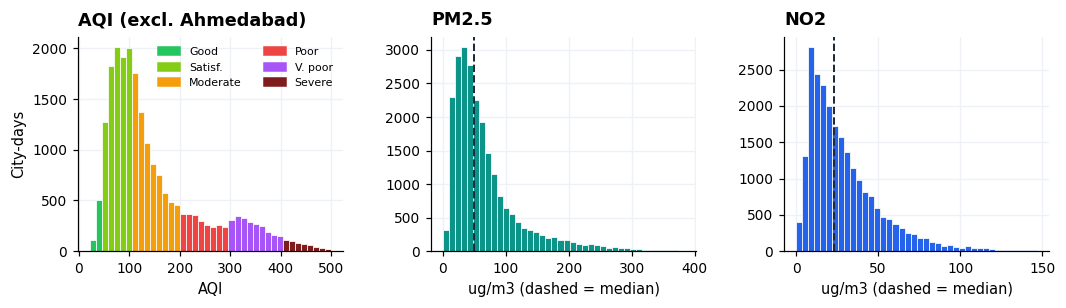

x-axes cut at the 99.5th percentile: PM2.5 383, NO2 147 ug/m3 (PM2.5 max is 950)


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(9.8, 2.9))

cuts = [50, 100, 200, 300, 400]
band_cols = ["#22c55e", "#84cc16", "#f59e0b", "#ef4444", "#a855f7", "#7f1d1d"]
counts, edges = np.histogram(df.aqi.dropna(), bins=40)
centres = (edges[:-1] + edges[1:]) / 2
cols_h = [band_cols[np.searchsorted(cuts, c)] for c in centres]
axes[0].bar(centres, counts, width=np.diff(edges), color=cols_h, edgecolor="white", linewidth=0.5)
axes[0].set_title("AQI (excl. Ahmedabad)", loc="left", pad=8)
axes[0].set_xlabel("AQI")
axes[0].set_ylabel("City-days")
axes[0].legend(handles=[Patch(color=band_cols[i], label=l) for i, l in
               enumerate(["Good", "Satisf.", "Moderate", "Poor", "V. poor", "Severe"])],
               ncol=2, fontsize=7.2, loc="upper right")

hi25 = df.pm25.quantile(0.995)
axes[1].hist(df.pm25, bins=40, range=(0, hi25), color=TEAL, edgecolor="white", linewidth=0.5)
axes[1].axvline(df.pm25.median(), color=INK, linestyle="--", linewidth=1.3)
axes[1].set_title("PM2.5", loc="left", pad=8)
axes[1].set_xlabel("ug/m3 (dashed = median)")

hi_n = df.no2.quantile(0.995)
axes[2].hist(df.no2, bins=40, range=(0, hi_n), color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].axvline(df.no2.median(), color=INK, linestyle="--", linewidth=1.3)
axes[2].set_title("NO2", loc="left", pad=8)
axes[2].set_xlabel("ug/m3 (dashed = median)")

fig.tight_layout(w_pad=2)
fig.savefig("img/f1_profile.png")
plt.show()
print(f"x-axes cut at the 99.5th percentile: PM2.5 {hi25:.0f}, NO2 {hi_n:.0f} ug/m3 (PM2.5 max is {df.pm25.max():.0f})")

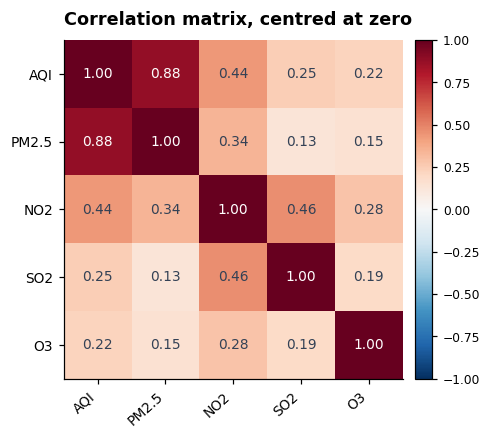

In [38]:
short = {"aqi": "AQI", "pm25": "PM2.5", "no2": "NO2", "so2": "SO2", "o3": "O3"}
m = corr.to_numpy()
labels = [short[c] for c in cols]

fig, ax = plt.subplots(figsize=(5.0, 4.0))
im = ax.imshow(m, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1))
ax.set_xticks(range(len(cols))); ax.set_xticklabels(labels, rotation=42, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(labels)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(m[i, j]) > 0.55 else "#334155")
ax.set_title("Correlation matrix, centred at zero", loc="left", pad=10)
cb = fig.colorbar(im, ax=ax, fraction=0.044, pad=0.03)
cb.ax.tick_params(labelsize=8)
fig.savefig("img/f2_corr.png")
plt.show()

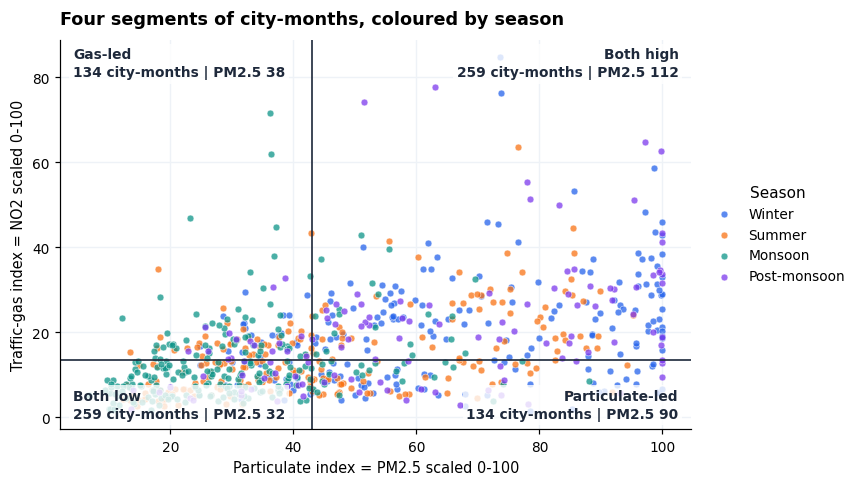

In [39]:
season_col = {"Winter": BLUE, "Summer": ORANGE, "Monsoon": TEAL, "Post-monsoon": PURPLE}
fig, ax = plt.subplots(figsize=(7.4, 4.6))
for s in SEASONS:
    d = cm[cm.season == s]
    ax.scatter(d.part, d.gas, s=20, alpha=0.75, color=season_col[s],
               edgecolor="white", linewidth=0.4, label=s)
ax.axvline(PC, color=INK, linewidth=1.1)
ax.axhline(GC, color=INK, linewidth=1.1)
ax.set_xlabel("Particulate index = PM2.5 scaled 0-100")
ax.set_ylabel("Traffic-gas index = NO2 scaled 0-100")
ax.set_title("Four segments of city-months, coloured by season", loc="left", pad=10)

corner = {"Gas-led": (0.02, 0.98, "left", "top"), "Both high": (0.98, 0.98, "right", "top"),
          "Both low": (0.02, 0.02, "left", "bottom"),
          "Particulate-led": (0.98, 0.02, "right", "bottom")}
for name, (x, y, ha, va) in corner.items():
    if name in seg.index:
        r = seg.loc[name]
        ax.text(x, y, f"{name}\n{int(r.n)} city-months | PM2.5 {r.pm25:.0f}",
                transform=ax.transAxes, ha=ha, va=va, fontsize=9, fontweight="bold",
                color=INK, linespacing=1.4,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=2.5))
ax.legend(title="Season", loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.savefig("img/f3_segments.png")
plt.show()

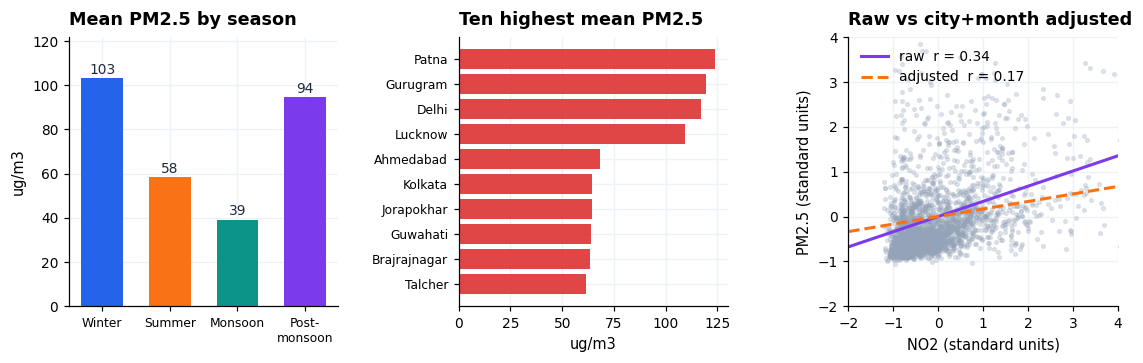

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.4))

# (a) mean PM2.5 by season
sv = by_season.pm25
axes[0].bar(["Winter", "Summer", "Monsoon", "Post-\nmonsoon"], sv.values,
            color=[BLUE, ORANGE, TEAL, PURPLE], width=0.62)
axes[0].set_ylim(0, sv.max() * 1.18)
for i, v in enumerate(sv.values):
    axes[0].text(i, v + sv.max() * 0.02, f"{v:.0f}", ha="center", fontsize=9, color=INK)
axes[0].set_title("Mean PM2.5 by season", loc="left", pad=8)
axes[0].set_ylabel("ug/m3")
axes[0].tick_params(axis="x", labelsize=8)

# (b) ten highest-PM2.5 cities
top = by_city.pm25.head(10)[::-1]
axes[1].barh(top.index, top.values, color=RED, alpha=0.85)
axes[1].set_title("Ten highest mean PM2.5", loc="left", pad=8)
axes[1].set_xlabel("ug/m3")
axes[1].tick_params(axis="y", labelsize=8)

# (c) raw versus adjusted PM2.5-NO2 link, standardised
zx = (df.no2 - df.no2.mean()) / df.no2.std()
zy = (df.pm25 - df.pm25.mean()) / df.pm25.std()
pick = np.random.default_rng(1).choice(len(df), size=min(2500, len(df)), replace=False)
axes[2].scatter(zx.iloc[pick], zy.iloc[pick], s=6, color=GREY, alpha=0.25)
g = np.linspace(-2, 4, 10)
axes[2].plot(g, r_raw * g, color=PURPLE, linewidth=2, label=f"raw  r = {r_raw:.2f}")
axes[2].plot(g, r_adj * g, "--", color=ORANGE, linewidth=2, label=f"adjusted  r = {r_adj:.2f}")
axes[2].set_xlim(-2, 4); axes[2].set_ylim(-2, 4)
axes[2].set_xlabel("NO2 (standard units)")
axes[2].set_ylabel("PM2.5 (standard units)")
axes[2].set_title("Raw vs city+month adjusted", loc="left", pad=8)
axes[2].legend(loc="upper left")

fig.tight_layout(w_pad=2.2)
fig.savefig("img/f4_season_adjusted.png")
plt.show()

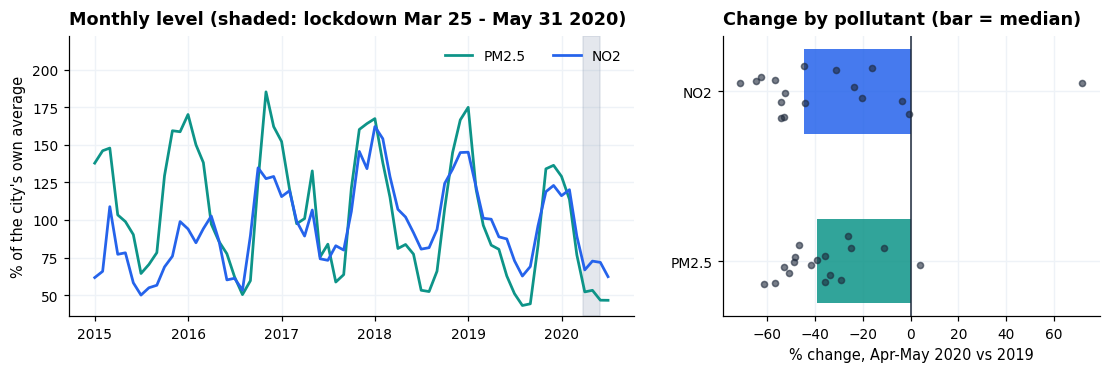

In [41]:
rel = df[["City", "year", "month"]].copy()
for c in ["pm25", "no2"]:
    rel[c] = df[c] / df.groupby("City")[c].transform("mean") * 100
mon = (rel.groupby(["City", "year", "month"])[["pm25", "no2"]].mean()
          .groupby(["year", "month"]).mean().reset_index())
mon["date"] = pd.to_datetime(dict(year=mon.year, month=mon.month, day=1))

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.5), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color=GREY, alpha=0.25)
axes[0].plot(mon.date, mon.pm25, color=TEAL, linewidth=1.8, label="PM2.5")
axes[0].plot(mon.date, mon.no2, color=BLUE, linewidth=1.8, label="NO2")
axes[0].set_ylim(top=max(mon.pm25.max(), mon.no2.max()) * 1.2)
axes[0].set_ylabel("% of the city's own average")
axes[0].set_title("Monthly level (shaded: lockdown Mar 25 - May 31 2020)", loc="left", pad=8)
axes[0].legend(loc="upper right", ncol=2)

med = chg.median()
ypos = np.arange(len(VARS))
axes[1].barh(ypos, med[VARS].values, color=[TEAL, BLUE], alpha=0.85, height=0.5)
rng = np.random.default_rng(3)
for i, v in enumerate(VARS):
    axes[1].scatter(chg[v], i + rng.uniform(-0.16, 0.16, len(chg)), s=16,
                    color=INK, alpha=0.6, zorder=3)
axes[1].axvline(0, color=INK, linewidth=1)
axes[1].set_yticks(ypos); axes[1].set_yticklabels(["PM2.5", "NO2"])
axes[1].set_xlabel("% change, Apr-May 2020 vs 2019")
axes[1].set_title("Change by pollutant (bar = median)", loc="left", pad=8)

fig.tight_layout(w_pad=2.4)
fig.savefig("img/f5_lever.png")
plt.show()

In [42]:
t = "Thiruvananthapuram"
print("NO2 Apr-May 2019:", w19[w19.City == t].no2.agg(["count", "mean"]).round(1).to_dict())
print("NO2 Apr-May 2020:", w20[w20.City == t].no2.agg(["count", "mean"]).round(1).to_dict())
print("\nmedian absolute change (ug/m3):")
print((b - a).median().round(1).to_string())


NO2 Apr-May 2019: {'count': 61.0, 'mean': 5.2}
NO2 Apr-May 2020: {'count': 61.0, 'mean': 9.0}

median absolute change (ug/m3):
pm25   -19.9
no2    -10.3


In [43]:
tab = pd.DataFrame({
    "pm25_2019": a.pm25, "pm25_2020": b.pm25,
    "pm25_abs": b.pm25 - a.pm25, "pm25_pct": chg.pm25,
    "no2_2019": a.no2, "no2_2020": b.no2,
    "no2_abs": b.no2 - a.no2, "no2_pct": chg.no2,
}).round(1)
print(tab.sort_values("no2_2019").to_string())
print("\nNO2 fell more in % terms in :", int((chg.no2 < chg.pm25).sum()), "of", len(chg), "cities")
print("NO2 fell more in abs terms in:", int(((b.no2 - a.no2) < (b.pm25 - a.pm25)).sum()), "of", len(chg), "cities")
tab.to_csv("data/lockdown_table.csv")


                    pm25_2019  pm25_2020  pm25_abs  pm25_pct  no2_2019  no2_2020  no2_abs  no2_pct
City                                                                                              
Thiruvananthapuram       24.1       17.8      -6.3     -26.2       5.2       9.0      3.8     72.0
Talcher                  37.3       33.2      -4.1     -11.0      13.8      13.8     -0.1     -0.5
Guwahati                 54.9       38.9     -16.0     -29.1      14.9      10.2     -4.7    -31.3
Chennai                  39.6       17.2     -22.4     -56.6      15.1       8.3     -6.8    -44.8
Amaravati                29.6       19.6     -10.1     -33.9      16.6       5.9    -10.8    -64.8
Mumbai                   18.0       18.7       0.7       3.9      18.0       7.8    -10.3    -56.9
Gurugram                 93.4       47.7     -45.7     -48.9      18.4      17.7     -0.7     -3.6
Kolkata                  42.8       20.2     -22.6     -52.8      23.4       8.7    -14.7    -62.8
Amritsar  

In [44]:
df.to_csv("data/aq_clean_daily.csv", index=False)
cm.to_csv("data/aq_city_month.csv", index=False)
print("saved to data/")

saved to data/
